In [22]:
"""
Question 3: Sales Visualization

Using the cleaned dataset from Question 1 ('sales_data.csv'), create the following visualizations:

1. Create a line plot showing daily sales trends over time
   - Include a 7-day moving average line

2. Create a bar plot showing:
   - Total sales by category
   - Include error bars representing standard deviation

3. Create a scatter plot showing:
   - Relationship between quantity and price
   - Color points by category
   - Add a trend line

Requirements:
- Use appropriate labels and titles
- Include a legend where necessary
- Use a consistent color scheme
- Save all plots as PNG files
"""

# Your code here

"\nQuestion 3: Sales Visualization\n\nUsing the cleaned dataset from Question 1 ('sales_data.csv'), create the following visualizations:\n\n1. Create a line plot showing daily sales trends over time\n   - Include a 7-day moving average line\n\n2. Create a bar plot showing:\n   - Total sales by category\n   - Include error bars representing standard deviation\n\n3. Create a scatter plot showing:\n   - Relationship between quantity and price\n   - Color points by category\n   - Add a trend line\n\nRequirements:\n- Use appropriate labels and titles\n- Include a legend where necessary\n- Use a consistent color scheme\n- Save all plots as PNG files\n"

In [23]:
import pandas as pd
import matplotlib.pyplot as plt

In [24]:
sales = pd.read_csv('../data/clean_sales_data.csv')
sales.info()
# Quick check to see if all the information is correct (1000 non null, sale_date is datetime)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  1000 non-null   int64  
 1   sale_id     1000 non-null   int64  
 2   sale_date   1000 non-null   object 
 3   category    1000 non-null   object 
 4   price       1000 non-null   float64
 5   quantity    1000 non-null   int64  
dtypes: float64(1), int64(3), object(2)
memory usage: 47.0+ KB


In [25]:
# Converting sale_date back to datetime
sales['sale_date'] = pd.to_datetime(sales['sale_date'])
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Unnamed: 0  1000 non-null   int64         
 1   sale_id     1000 non-null   int64         
 2   sale_date   1000 non-null   datetime64[ns]
 3   category    1000 non-null   object        
 4   price       1000 non-null   float64       
 5   quantity    1000 non-null   int64         
dtypes: datetime64[ns](1), float64(1), int64(3), object(1)
memory usage: 47.0+ KB


### 1. 7-day moving average and trendline

In [26]:
# 7 day moving average of daily sales (today + 6 days past)

sales['daily_sales'] = sales.groupby('sale_date')['price'].transform('sum')
daily_sales = sales['daily_sales']
daily_sales_7d = sales['daily_sales'].rolling(window=7).mean()

daily_sales_7d

0             NaN
1             NaN
2             NaN
3             NaN
4             NaN
          ...    
995     95.756045
996    103.626495
997    102.767177
998     95.030784
999    107.330906
Name: daily_sales, Length: 1000, dtype: float64

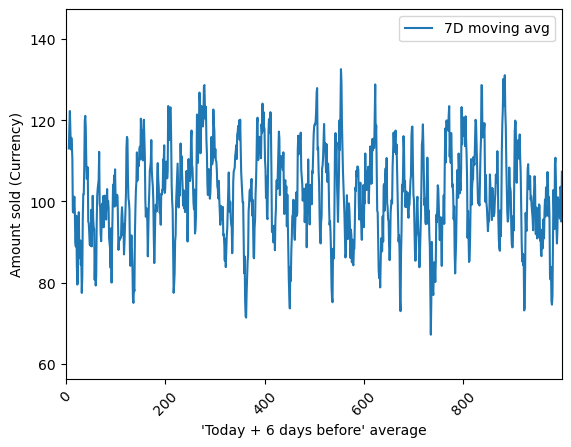

In [27]:
# Visualizing the 7-day average daily sale 
plt.plot(daily_sales_7d.index, daily_sales_7d, label='7D moving avg')
plt.xticks(rotation=45)

# Adjusting y limits to better visualize the plot
plt.ylim(daily_sales_7d.mean()-4*daily_sales_7d.std(), daily_sales_7d.mean()+4*daily_sales_7d.std())
plt.xlim(daily_sales_7d.index[0], daily_sales_7d.index[-1])
plt.xlabel("'Today + 6 days before' average")
plt.ylabel("Amount sold (Currency)")
plt.legend()
plt.savefig('figs/7d_moving_average_notrend.png')
plt.show()

In [28]:
# This plot isn't all that useful, since it has an enormous variance
mean = daily_sales_7d.mean()
var = daily_sales_7d.var()

print(f"Mean: {mean}, Variance: {var}")

Mean: 101.79668500658627, Variance: 129.90752466280796


In [29]:
# As requested, we can calculate the trend line:
import numpy as np
from numpy import polyfit, poly1d

trendline = poly1d(polyfit(range(len(daily_sales.index)), daily_sales, 1))
trendline

poly1d([-2.51190688e-05,  1.01895599e+02])

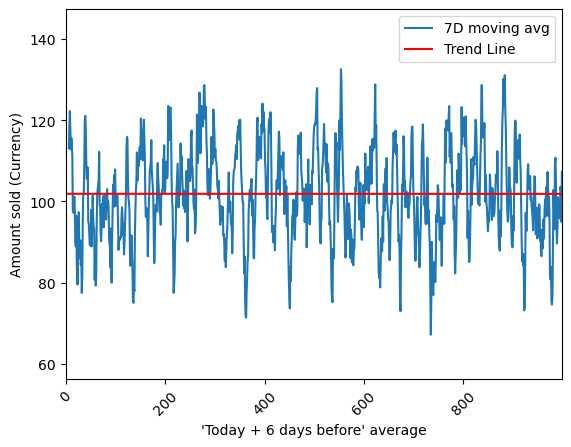

In [30]:
plt.plot(daily_sales_7d.index, daily_sales_7d, label='7D moving avg')
plt.plot(range(len(daily_sales.index)), trendline(range(len(daily_sales.index))), label='Trend Line', color='r')
plt.xticks(rotation=45)
plt.ylim(daily_sales_7d.mean()-4*daily_sales_7d.std(), daily_sales_7d.mean()+4*daily_sales_7d.std())
plt.xlim(daily_sales_7d.index[0], daily_sales_7d.index[-1])
plt.xlabel("'Today + 6 days before' average")
plt.ylabel("Amount sold (Currency)")
plt.legend()
plt.savefig('figs/7d_moving_average_trend.png')
plt.show()

### 2. Bar plot with error bars

In [31]:
sales_cat = sales.groupby('category').agg(total=('price', 'sum'), std=('price', 'std'))
sales_cat

,total,std
category,,
Books,18203.550104,31.113079
Clothing,19185.821591,29.217836
Electronics,23927.027991,26.495097
Home & Garden,20625.604124,32.887988
Sports,19941.048310,28.875168


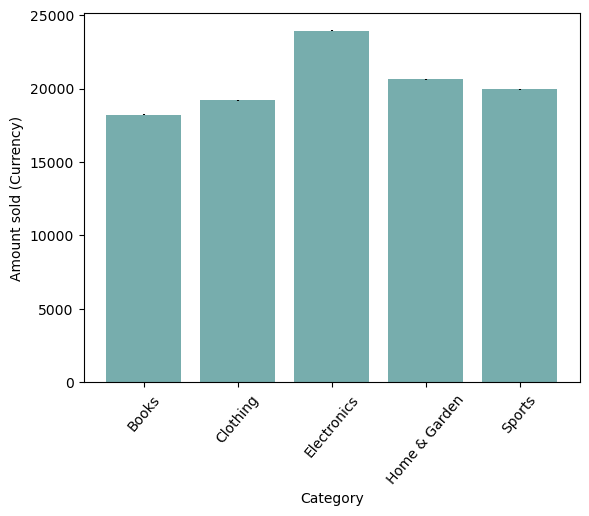

In [32]:
cats = sales_cat.index

plt.bar(cats, sales_cat['total'], yerr=sales_cat['std'], color="#00666688")
plt.xticks(rotation=50)
plt.xlabel("Category")
plt.ylabel("Amount sold (Currency)")
plt.savefig('figs/sales_by_category.png')
plt.show()

### 3. Scatter plot

In [33]:
quants = sales.groupby(['quantity', 'category'])['price'].sum()
quants = quants.reset_index()
quants.head()

,quantity,category,price
0,1,Books,2152.371434
1,1,Clothing,1590.206386
2,1,Electronics,3290.847490
3,1,Home & Garden,1997.304612
4,1,Sports,2162.721599


In [ ]:
from scipy.stats import linregress

def y(m, b, x):
    return m*x + b

colors = ['red', 'blue', 'darkgreen', 'orange', 'black']

for i in range(len(cats)):
    # loops through categories, and plots the price for a given catgory, for a given quantity
    category = quants[quants['category'] == cats[i]]
    plt.scatter(category['quantity'], category['price'], label=cats[i], color=colors[i])
    
    # # Finds the line that best fits the data for each category
    m, b, c, c, c = linregress(category['quantity'], category['price'])
    xs = np.linspace(category['quantity'].min(), category['quantity'].max(), 500)
    ys = y(m, b, xs)
    
    # Plots the bet fitting line
    plt.plot(xs, ys, color=colors[i], linestyle='-', lw = 1.3, label=f'^ best fit')
plt.legend(loc=(1.0, 0.4))
plt.xlabel("Quantity bought")
plt.ylabel("Average price of quantity bought (Currency)")
plt.savefig('figs/scatter_plot.png')
plt.show()